# 📘 Notebook 06: Activation Functions, the Non-Linearity Between Layers

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **fifteen minutes** on an ordinary processor. Differences between modern activations (ReLU, GELU, SiLU) are small on a problem this size; the dramatic differences appear with **depth**, which is why Section 3 uses deep networks.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain why a network needs a **non-linear** activation at all
- Plot the common activations (**sigmoid, tanh, ReLU, Leaky ReLU, ELU, GELU, SiLU**) and their **derivatives**
- Compare them on a shallow and on a **deep** network
- Explain **saturation** and the **dying ReLU** problem, and measure them
- Choose a sensible default

> **Prerequisites:** [Notebook 05: Neurons and Layers](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/05_neurons_and_layers.ipynb).
>
> 🔭 **Why this notebook matters:** the activation function is a one-word choice in the code, and for shallow networks it barely matters; for deep ones it can decide whether training works at all. Knowing why lets you read the defaults of modern models (GELU in Transformers, SiLU in many vision models) instead of copying them.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


## 1. Why non-linear?

Without an activation, two layers $W_2(W_1 x)$ are the same as one layer with the matrix $W_2 W_1$: any stack of linear layers is a **single linear function**, however deep. The activation bends each layer's output, and only then can depth build complex patterns.

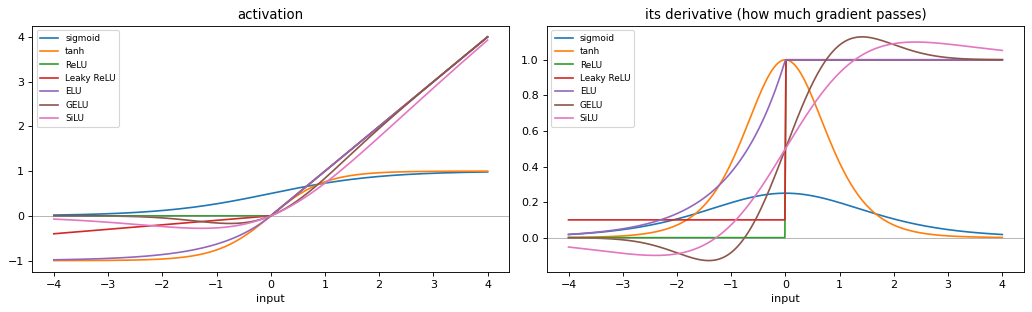

In [2]:
z = torch.linspace(-4, 4, 400, requires_grad=True)
acts = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "ReLU": F.relu, "Leaky ReLU": lambda x: F.leaky_relu(x, 0.1),
        "ELU": F.elu, "GELU": F.gelu, "SiLU": F.silu}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, f in acts.items():
    y = f(z)
    grad, = torch.autograd.grad(y.sum(), z)
    axes[0].plot(z.detach(), y.detach(), label=name)
    axes[1].plot(z.detach(), grad, label=name)
axes[0].set_title("activation"); axes[1].set_title("its derivative (how much gradient passes)")
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.5); ax.legend(fontsize=8); ax.set_xlabel("input")
plt.tight_layout()
plt.show()

**What we see.** The left panel shows the shapes, the right panel what matters for training: **how much gradient each function lets through**.
- **Sigmoid** passes at most **0.25** of the gradient (at 0) and almost nothing for inputs beyond about ±4: it **saturates**. Through ten layers, a factor of 0.25 or less per layer leaves almost nothing.
- **Tanh** passes up to 1 near zero, but saturates in the same way for large inputs.
- **ReLU** passes the gradient **unchanged** (1) for positive inputs and **nothing** (0) for negative ones. Leaky ReLU and ELU keep a small slope on the negative side.
- **GELU** and **SiLU** are smooth versions of ReLU: close to it for large inputs, with a small dip below zero.

## 2. A shallow network: does it matter?

One hidden layer of 128 neurons, 15 epochs, each activation, 3 seeds each.

In [3]:
activations = {"identity (none)": nn.Identity, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "ReLU": nn.ReLU,
               "Leaky ReLU": lambda: nn.LeakyReLU(0.1), "ELU": nn.ELU, "GELU": nn.GELU, "SiLU": nn.SiLU}
shallow = {}
for name, act in activations.items():
    scores = [fit(make_mlp(hidden=(128,), activation=act), epochs=15, seed=s)["val acc"].max() for s in range(3)]
    shallow[name] = {"mean best val acc": np.mean(scores), "std": np.std(scores)}
pd.DataFrame(shallow).T.sort_values("mean best val acc", ascending=False).round(4)

,mean best val acc,std
tanh,0.862,0.001
GELU,0.861,0.002
SiLU,0.860,0.002
sigmoid,0.859,0.002
ReLU,0.859,0.002
Leaky ReLU,0.858,0.001
ELU,0.857,0.002
identity (none),0.836,0.002


**What we see.** With one hidden layer the choice barely matters: every non-linear activation lands between **85.7%** and **86.2%**, with a seed-to-seed spread of 0.1 to 0.2 points, so their order is not meaningful. Even tanh and sigmoid, the "old" functions, are fine here. The one clear result is the **identity** (no activation): **83.6%**, more than two points behind. Without a non-linearity the network is just a linear classifier, which on Fashion-MNIST is decent but clearly weaker.

## 3. A deep network: now it matters

Eight hidden layers of 64 neurons, plain SGD with learning rate 0.05 (no momentum, no normalisation, the setting where the old problems show up), 15 epochs.

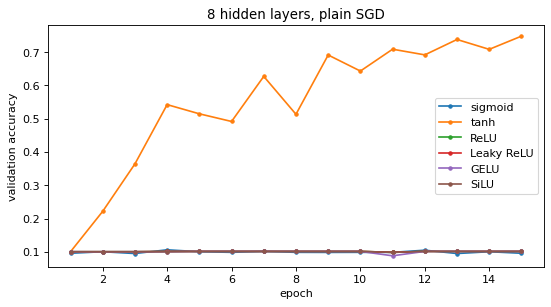

,val acc after 1 epoch,after 5,after 15
sigmoid,0.096,0.100,0.096
tanh,0.100,0.515,0.748
ReLU,0.100,0.101,0.101
Leaky ReLU,0.100,0.101,0.101
GELU,0.100,0.101,0.101
SiLU,0.100,0.101,0.101


In [4]:
deep = {}
for name in ["sigmoid", "tanh", "ReLU", "Leaky ReLU", "GELU", "SiLU"]:
    h = fit(make_mlp(hidden=(64,) * 8, activation=activations[name]), epochs=15, lr=0.05, optimizer="sgd")
    deep[name] = h
fig, ax = plt.subplots(figsize=(8, 4))
for name, h in deep.items():
    ax.plot(h.index, h["val acc"], marker="o", ms=3, label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.legend(); ax.set_title("8 hidden layers, plain SGD")
plt.show()
pd.DataFrame({n: {"val acc after 1 epoch": h["val acc"].iloc[0], "after 5": h["val acc"].iloc[4], "after 15": h["val acc"].iloc[-1]} for n, h in deep.items()}).T.round(3)

**What we see.** This is **not** the textbook picture, and it is worth understanding why. With eight layers and plain SGD:
- **Sigmoid** does not learn at all (10% is random guessing among ten classes), as expected from saturation.
- **Tanh** is the only one that learns, slowly and unevenly, to **74.8%** after 15 epochs.
- **ReLU, Leaky ReLU, GELU and SiLU** also stay at **10%** for all 15 epochs.

The reason is not the activation alone but its **combination with the initial weights**. PyTorch's default initialisation draws weights that are a little too small for a deep stack, so the signal weakens through every layer. It weakens for tanh too, but ReLU also throws away the negative half at each layer: in a quick check with random inputs, after eight layers the ReLU signal was about half as strong as the tanh signal, and what remained came mostly from the biases rather than from the image. The network's output then hardly depends on its input, and plain SGD with no momentum makes almost no progress. Section 4 measures this directly, and **Notebook 08** shows how the right initialisation for ReLU (He et al., 2015) fixes it. The lesson: an activation function is never chosen alone; it comes with an initialisation, an optimiser and, in modern networks, normalisation.

## 4. Measuring the two classic problems

**Saturation:** sigmoid and tanh flatten out for large inputs, so their derivative is almost zero there, and gradients shrink as they pass back through many layers. **Dying ReLU:** a ReLU neuron whose input is negative for every example outputs zero and passes no gradient; it can never recover. We measure both in the deep networks, at the start of training.

In [5]:
def first_layer_gradient(act, seed=0):
    torch.manual_seed(seed)
    m = make_mlp(hidden=(64,) * 8, activation=act)
    F.cross_entropy(m(X_train[:512]), y_train[:512]).backward()
    return m[0].weight.grad.norm().item(), m[-1].weight.grad.norm().item()

rows = {}
for name in ["sigmoid", "tanh", "ReLU", "GELU"]:
    first, last = first_layer_gradient(activations[name])
    rows[name] = {"gradient at first layer": first, "at last layer": last, "ratio first / last": first / last}
pd.DataFrame(rows).T.round(5)

,gradient at first layer,at last layer,ratio first / last
sigmoid,0.000e+00,0.249,0.000
tanh,2.799e-02,0.026,1.073
ReLU,2.430e-03,0.017,0.142
GELU,2.200e-04,0.011,0.020


In [6]:
def dead_share(model):
    model.eval()
    dead, total = 0, 0
    x = X_val
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            if isinstance(layer, nn.ReLU):
                dead += (x.max(0).values == 0).sum().item(); total += x.shape[1]
    return dead / total

for lr in [1e-3, 1e-2, 5e-2]:
    m = make_mlp(hidden=(64,) * 4)
    fit(m, epochs=10, lr=lr)
    print(f"Adam, lr {lr:g}: share of ReLU neurons that never fire on the validation set: {dead_share(m):.3f}")

Adam, lr 0.001: share of ReLU neurons that never fire on the validation set: 0.078


Adam, lr 0.01: share of ReLU neurons that never fire on the validation set: 0.160


Adam, lr 0.05: share of ReLU neurons that never fire on the validation set: 0.684


**What we see.** The first table measures the gradient at the start of training, in the first and last layers of the 8-layer networks:
- **Sigmoid**: the first layer receives a gradient of practically **zero** (below 0.00001) while the last receives 0.25. Saturation in action: nothing reaches the early layers, so they never learn.
- **Tanh**: the first layer receives about the **same** gradient as the last (ratio 1.07). This is why it was the only one that learned in Section 3.
- **ReLU**: the first layer gets only **14%** of the last layer's gradient, and **GELU** only **2%**. With the default initialisation, the gradient fades on its way back to the early layers, as explained above.

The second measurement shows **dying ReLU** in a 4-layer network trained with Adam: at learning rate 0.001, **7.8%** of the hidden neurons never fire on any validation image; at 0.01, **16%**; at 0.05, **68%**. Large updates push neurons into the region where their input is always negative, and since they then pass no gradient, they stay dead for good.

## ⚠️ Common pitfalls

- **Forgetting the activation** between linear layers: the network collapses into a linear model.
- **Sigmoid or tanh in deep hidden layers** without normalisation: saturation slows or stops learning. (They remain fine in **outputs** and gates, as in LSTMs.)
- **A learning rate that is too high with ReLU:** large updates can push neurons into the dead zone for good.
- **Expecting a new activation to fix a bad setup.** Activation choice matters far less than learning rate, initialisation and normalisation.

## ✏️ Exercises

### Exercise 1 (Rescue the sigmoid)
Train the 8-layer sigmoid network of Section 3 with **Adam** (learning rate 0.001) instead of plain SGD. Does it learn now? Why might an adaptive optimiser help?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
h = fit(make_mlp(hidden=(64,) * 8, activation=nn.Sigmoid), epochs=15, lr=1e-3, optimizer="adam")
print("sigmoid, 8 layers, Adam: val acc after 15 epochs", round(h["val acc"].iloc[-1], 4))
```

*Only a little: in our run it reaches about 20% after 15 epochs, better than 10% but far from useful. Adam rescales each weight's step by the size of its recent gradients, which helps the early layers, but eight saturating layers still pass almost no information forward. The real fixes are a non-saturating activation, a suitable initialisation (Notebook 08) or normalisation (Notebook 10).*
</details>

### Exercise 2 (Leaky versus plain at a high learning rate)
Repeat the dead-neuron measurement at learning rate 0.05 with `nn.LeakyReLU(0.1)` instead of ReLU (count neurons whose output is never positive). Does the leak help?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def never_positive(model):
    model.eval(); x = X_val; dead = total = 0
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            if isinstance(layer, nn.LeakyReLU):
                dead += (x.max(0).values <= 0).sum().item(); total += x.shape[1]
    return dead / total

m = make_mlp(hidden=(64,) * 4, activation=lambda: nn.LeakyReLU(0.1))
h = fit(m, epochs=10, lr=5e-2)
print("Leaky ReLU, lr 0.05: never-positive share", round(never_positive(m), 3), " val acc", round(h["val acc"].iloc[-1], 4))
```

*In our run about 10% of the Leaky ReLU neurons were never positive, against 68% dead ReLU neurons at the same learning rate, and the network reached 73% validation accuracy. A Leaky ReLU can still sit on its negative side, but it keeps passing a small gradient there, so it can recover. That is its whole purpose.*
</details>

## 🔑 Key takeaways

- Activations make depth meaningful; without them a network is linear.
- On **shallow** networks the choice barely matters (as long as there is one).
- On **deep** networks, the activation must match the **initialisation**: sigmoid saturates and blocks the gradient; ReLU, GELU and SiLU need an initialisation designed for them (Notebook 08), otherwise the signal fades layer by layer.
- **Dying ReLU** appears with large learning rates; Leaky ReLU, GELU and SiLU avoid it.
- A sensible default: **ReLU**, or **GELU / SiLU** as in modern architectures.

---
**Next:** *Notebook 07: Optimisers*, SGD, momentum, RMSprop and Adam compared.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*